# P6. 리뷰 감성 파이프라인

네이버 영화 리뷰 5만 건을 MongoDB 에 문서로 적재하고, Spark 로 빈 글 · 중복 · 너무 짧은 글을 걸러 낸 뒤, 기준 감성 모델(TF-IDF + 로지스틱 회귀)과 주제 태깅 결과를 Iceberg 테이블로 쌓아 주제별 감성을 집계합니다.

- 단계: 개별 프로젝트 · 비정형 · 예상 2~3일
- 실행 환경: Google Colab(브라우저만 있으면 됩니다)
- 데이터: Naver Sentiment Movie Corpus(NSMC, Lucy Park) — ratings_test.txt 5만 건, CC0 1.0(퍼블릭 도메인)
- 데이터: (선택) OpenAI gpt-4o-mini — 키가 있을 때 표본 50건 태깅

셀을 위에서부터 차례로 실행하세요. 각 단계 끝의 **확인 포인트** 숫자가 같게 나오면 다음 단계로 갑니다.
따라하기를 한 번 끝냈다면 같은 내용의 [빈칸 노트북](https://colab.research.google.com/github/aebonlee/materials/blob/main/data-eng/projects/P6/P6_blank.ipynb)으로 다시 쳐 보세요.

리뷰 데이터는 대표적인 **비정형 데이터**입니다. 글 길이가 제각각이고, 빈 글 · 같은 글 · 「.」 하나짜리 글이 섞여 있습니다.
이 프로젝트에서는 실제 리뷰 5만 건을 데이터 엔지니어의 방식으로 다룹니다 — 원본을 문서 DB 에 그대로 받아 두고, 정제는 Spark 로, 결과는 분석용 테이블(Iceberg)로.

```text
NSMC 리뷰(TSV) → MongoDB 적재(원본 보관) → Spark 정제(빈 글 · 짧은 글 · 중복)
  → 기준 모델(TF-IDF + 로지스틱 회귀) 감성 · 규칙 주제 태깅 → (키가 있으면) gpt-4o-mini 표본 50건 비교
  → Iceberg 테이블(스냅샷 2개) → DuckDB 로 주제별 감성 집계
```

NSMC 는 리뷰마다 **정답 감성(긍정 1 · 부정 0)**이 붙어 있어서, 모델이 얼마나 맞히는지 숫자로 잴 수 있습니다.
다 끝내면 다음을 말할 수 있습니다.

- 원본 5만 건 중 분석에 쓸 수 있는 리뷰가 몇 건이고, 무엇을 왜 뺐는지
- 키 없이 만든 기준 모델의 정확도 — LLM 을 붙이기 전에 넘어야 할 기준선
- 연기 · 스토리 · 연출 · 영상 · 음악 가운데 어느 주제의 리뷰가 가장 부정적인지

## 1단계 · 준비 — 라이브러리 · Java · 데이터

Spark(5주차)는 Java 가 필요하고, Iceberg(18장)는 파이썬 라이브러리 `pyiceberg` 로 다룹니다. 카탈로그는 파일 하나짜리 SQLite 로 둡니다 — 서버가 없어도 Iceberg 테이블을 만들 수 있습니다.
Colab 에 없는 패키지만 설치합니다.

In [ ]:
import os, sys, io, json, re, time, shutil, tarfile, platform, subprocess, importlib.util, urllib.request
import pandas as pd
import numpy as np
import duckdb

def need(mod, pkg=None):
    """없는 패키지만 설치합니다."""
    if importlib.util.find_spec(mod) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg or mod], check=True)

need("pymongo")
need("pyspark")
need("pyiceberg", "pyiceberg[sql-sqlite,pyarrow]")
need("sklearn", "scikit-learn")

if shutil.which("java") is None:                      # Colab 에 Java 가 없을 때만 설치합니다
    subprocess.run("apt-get install -y -qq openjdk-17-jre-headless > /dev/null", shell=True, check=True)
    os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
print(subprocess.run(["java", "-version"], capture_output=True, text=True).stderr.splitlines()[0])

openjdk version "21.0.11" 2026-04-21 LTS


데이터는 네이버 영화 리뷰 말뭉치 NSMC(Naver Sentiment Movie Corpus)의 평가용 파일 `ratings_test.txt` 입니다.
원작자(Lucy Park)가 **CC0 1.0**(퍼블릭 도메인)으로 공개해서 자유롭게 고쳐 쓰고 다시 나눌 수 있습니다. 내용은 원본 그대로이고 gzip 으로 압축만 했습니다.

In [ ]:
DATA = "https://raw.githubusercontent.com/aebonlee/materials/main/data-eng/projects/data/"

def fetch(name):
    """프로젝트 데이터를 ./data 폴더에 한 번만 받아 둡니다."""
    os.makedirs("data", exist_ok=True)
    dst = os.path.join("data", name)
    if not os.path.exists(dst):
        local = os.environ.get("DE_DATA_LOCAL")          # 오프라인 실습용 — 자료 폴더가 내 컴퓨터에 있을 때
        if local:
            shutil.copy(os.path.join(local, name), dst)
        else:
            urllib.request.urlretrieve(DATA + name, dst)
    return dst

path = fetch("nsmc_ratings_test.txt.gz")
reviews = pd.read_csv(path, sep="\t", dtype={"document": str})
print(reviews.shape)
reviews.head(3)

(50000, 3)


,id,document,label
0,6270596,굳 ㅋ,1
1,9274899,GDNTOPCLASSINTHECLUB,0
2,8544678,뭐야 이 평점들은.... 나쁘진 않지만 10점 짜리는 더더욱 아니잖아,0


> **확인 포인트** — `(50000, 3)` — 열은 `id` · `document`(리뷰 글) · `label`(1 긍정, 0 부정)입니다.

In [ ]:
assert reviews.shape == (50000, 3) and list(reviews.columns) == ["id", "document", "label"]

> **Aebon's Tip** — 원본은 github.com/e9t/nsmc 에 있습니다. 학습용 `ratings_train.txt`(15만 건)도 같은 형식이라, 파일 이름만 바꾸면 이 노트북이 그대로 돕니다(시간은 세 배쯤 걸립니다).

## 2단계 · MongoDB 띄우기

Colab 에는 MongoDB 서버가 없습니다. MongoDB 는 설치 없이 압축만 풀면 도는 실행 파일(`mongod`)을 공식 사이트에서 내려받을 수 있어서, 그것을 받아 노트북 뒤에서 띄웁니다.
내 컴퓨터(macOS)에서 돌리면 macOS 판을, Colab(Linux)에서는 Ubuntu 22.04 판을 고릅니다. 2주차 9장에서 Docker 로 띄운 것과 같은 MongoDB 7.0 입니다.

In [ ]:
VER = "7.0.14"
if platform.system() == "Linux":
    pkg = f"mongodb-linux-x86_64-ubuntu2204-{VER}"
    url = f"https://fastdl.mongodb.org/linux/{pkg}.tgz"
else:                                                  # macOS — 애플 실리콘이면 arm64 판
    arch = "arm64" if platform.machine() == "arm64" else "x86_64"
    pkg = f"mongodb-macos-{arch}-{VER}"
    url = f"https://fastdl.mongodb.org/osx/{pkg}.tgz"

MONGOD = os.path.join("mongodb", pkg, "bin", "mongod")
if not os.path.exists(MONGOD):
    os.makedirs("mongodb", exist_ok=True)
    tgz, _ = urllib.request.urlretrieve(url, os.path.join("mongodb", pkg + ".tgz"))
    with tarfile.open(tgz) as t:
        t.extractall("mongodb")
print(MONGOD, os.path.exists(MONGOD))

mongodb/mongodb-macos-x86_64-7.0.14/bin/mongod True


기본 포트 27017 은 내 컴퓨터에서 다른 MongoDB(Docker 등)가 이미 쓰고 있을 수 있어 **27027** 을 씁니다.
서버가 뜨기 전에 접속하면 실패합니다. 먼저 일부러 실패를 봅니다.

In [ ]:
import pymongo
from pymongo.errors import ServerSelectionTimeoutError

PORT = 27027
try:
    pymongo.MongoClient(port=PORT, serverSelectionTimeoutMS=1000).admin.command("ping")
except ServerSelectionTimeoutError as e:
    print("접속 실패(아직 서버 없음):", str(e)[:70])

접속 실패(아직 서버 없음): localhost:27027: [Errno 61] Connection refused (configured timeouts: s


In [ ]:
os.makedirs("mongo-data", exist_ok=True)
mongod = subprocess.Popen([MONGOD, "--dbpath", "mongo-data", "--port", str(PORT), "--bind_ip", "127.0.0.1",
                           "--logpath", "mongo-data/mongod.log"],
                          stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)

client = pymongo.MongoClient(port=PORT, serverSelectionTimeoutMS=1000)
for _ in range(30):                                    # 뜰 때까지 1초씩 최대 30번 기다립니다
    try:
        client.admin.command("ping")
        break
    except ServerSelectionTimeoutError:
        time.sleep(1)
print("MongoDB", client.server_info()["version"])

MongoDB 7.0.14


> **확인 포인트** — `MongoDB 7.0.14` 가 찍힙니다.

In [ ]:
assert client.server_info()["version"] == VER

> **자주 겪는 오류** — 셀을 다시 실행해 `mongod` 를 두 번 띄우면 두 번째는 「포트가 이미 쓰이는 중」이라 바로 꺼집니다. 첫 번째 서버가 살아 있으니 그대로 이어서 쓰면 됩니다.
> 완전히 끄려면 마지막 단계의 `mongod.terminate()` 를 실행하세요.

## 3단계 · MongoDB 에 원본 적재 — 리뷰 하나가 문서 하나

원본은 고치지 않고 그대로 넣습니다. 정제 기준이 바뀌어도 언제든 원본에서 다시 시작할 수 있게 하려는 것입니다.
NSMC 의 `id` 를 문서의 `_id` 로 쓰면 같은 리뷰가 두 번 들어가는 것을 MongoDB 가 막아 줍니다(9장).

In [ ]:
col = client["reviewdb"]["nsmc"]
col.drop()                                             # 다시 실행해도 같은 결과가 나오게 비우고 시작

docs = [{"_id": int(r.id),
         "text": None if pd.isna(r.document) else r.document,
         "label": int(r.label),
         "source": "nsmc_test"}
        for r in reviews.itertuples()]
res = col.insert_many(docs)
print("넣은 문서:", len(res.inserted_ids), "/ 컬렉션:", col.count_documents({}))

넣은 문서: 50000 / 컬렉션: 50000


> **확인 포인트** — **50,000건**이 들어갑니다.

In [ ]:
assert col.count_documents({}) == 50000

같은 문서를 한 번 더 넣어 봅니다. `_id` 가 겹쳐서 실패합니다.

In [ ]:
from pymongo.errors import BulkWriteError
try:
    col.insert_many(docs[:3])
except BulkWriteError as e:
    print("실패:", e.details["writeErrors"][0]["errmsg"][:90])
print("그대로:", col.count_documents({}))

실패: E11000 duplicate key error collection: reviewdb.nsmc index: _id_ dup key: { _id: 6270596 }
그대로: 50000


MongoDB 의 집계 파이프라인으로 감성별 건수와 빈 글을 셉니다.

In [ ]:
by_label = list(col.aggregate([
    {"$group": {"_id": "$label", "n": {"$sum": 1}}},
    {"$sort": {"_id": 1}},
]))
print(by_label)
print("빈 글(text 가 null):", col.count_documents({"text": None}))

[{'_id': 0, 'n': 24827}, {'_id': 1, 'n': 25173}]
빈 글(text 가 null): 3


> **확인 포인트** — 부정(0) **24,827건** · 긍정(1) **25,173건**, 글이 비어 있는 문서가 **3건**입니다. 긍정 · 부정이 거의 반반이라 정확도를 그대로 믿어도 됩니다.

In [ ]:
assert [d["n"] for d in by_label] == [24827, 25173] and col.count_documents({"text": None}) == 3

## 4단계 · Spark 로 정제 — 빈 글 · 짧은 글 · 중복

MongoDB 에서 문서를 꺼내 Spark 데이터프레임으로 옮깁니다. 수천만 건이면 MongoDB Spark Connector 로 바로 읽지만, 5만 건은 pymongo 로 꺼내 넘기는 편이 간단합니다.

In [ ]:
from pyspark.sql import SparkSession, functions as F

os.environ["PYSPARK_PYTHON"] = sys.executable        # Spark 일꾼도 이 노트북과 같은 파이썬을 쓰게 합니다
spark = (SparkSession.builder.master("local[2]").appName("P6-reviews")
         .config("spark.sql.shuffle.partitions", "8")
         .config("spark.ui.enabled", "false")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

rows = pd.DataFrame(list(col.find({}, {"_id": 1, "text": 1, "label": 1}))).rename(columns={"_id": "id"})
sdf = spark.createDataFrame(rows[["id", "text", "label"]], schema="id LONG, text STRING, label INT")
print(spark.version, sdf.count())

3.5.3 50000


Spark 의 열은 파이썬 값이 아니라 「나중에 계산할 식」입니다. 그래서 파이썬의 `len()` 을 쓰면 실패합니다. 일부러 해 봅니다.

In [ ]:
try:
    sdf.filter(len(sdf.text) > 1)
except TypeError as e:
    print("실패:", e)

실패: object of type 'Column' has no len()


글을 고르게 만듭니다(정규화). 한글 · 영문 · 숫자만 남기고 나머지 기호는 빈칸으로 바꾼 뒤, 빈칸을 하나로 줄이고 영문은 소문자로 맞춥니다.
`length` 는 빈칸을 뺀 글자 수입니다.

In [ ]:
norm = F.lower(F.trim(F.regexp_replace(
    F.regexp_replace(F.coalesce(F.col("text"), F.lit("")), r"[^가-힣ㄱ-ㅎㅏ-ㅣa-zA-Z0-9]", " "),
    r"\s+", " ")))
s1 = (sdf.withColumn("norm", norm)
         .withColumn("length", F.length(F.regexp_replace("norm", " ", ""))))

empty = s1.filter(F.col("text").isNull() | (F.trim("text") == "")).count()
short = s1.filter("length < 2").count()
print("빈 글:", empty, "/ 정규화 뒤 두 글자가 안 되는 글:", short)

빈 글: 3 / 정규화 뒤 두 글자가 안 되는 글: 333


> **확인 포인트** — 빈 글 **3건**, 정규화 뒤 두 글자가 안 되는 글(빈 글 포함) **333건**입니다. 「.」 · 「ㅋ」 처럼 감성을 판단할 근거가 없는 글입니다.

In [ ]:
assert empty == 3 and short == 333

다음은 중복입니다. 정규화한 글이 같으면 같은 리뷰로 봅니다. 그런데 같은 글에 **정답이 서로 다른** 경우가 있습니다 — 이런 글은 모델에게 서로 다른 답을 가르치므로 통째로 뺍니다.

In [ ]:
kept = s1.filter("length >= 2")
g = kept.groupBy("norm").agg(
    F.min("id").alias("id"),
    F.count("*").alias("n"),
    F.countDistinct("label").alias("n_label"))
print("같은 글 묶음(2건 이상):", g.filter("n > 1").count(), "/ 정답이 엇갈린 글:", g.filter("n_label > 1").count())

clean = (g.filter("n_label = 1").select("id")
          .join(kept, "id")
          .select("id", "text", "norm", "label", "length"))
clean_pd = clean.orderBy("id").toPandas()
print("정제 후:", len(clean_pd))

같은 글 묶음(2건 이상): 398 / 정답이 엇갈린 글: 51


정제 후: 48532


> **확인 포인트** — 같은 글 묶음 **398개**, 그중 정답이 엇갈린 글 **51개**를 빼고 **48,532건**이 남습니다.
> 50,000 − 333(짧은 글) = 49,667건에서 같은 글을 하나로 줄이고 엇갈린 글을 뺀 결과입니다.

In [ ]:
assert g.filter("n > 1").count() == 398 and g.filter("n_label > 1").count() == 51 and len(clean_pd) == 48532

> **자주 겪는 오류** — `dropDuplicates(["norm"])` 로 지우면 어느 줄이 남을지 Spark 가 정합니다(파티션 순서에 따라 달라질 수 있습니다). 여기서는 묶음마다 `min("id")` 로 남길 줄을 정해 두어 몇 번을 돌려도 같은 결과가 나옵니다.

## 5단계 · 기준 모델 — TF-IDF + 로지스틱 회귀

LLM 에 맡기기 전에 키 없이 도는 **기준 모델**부터 만듭니다. 기준선이 있어야 LLM 이 정말 나은지 말할 수 있습니다.
한국어는 띄어쓰기가 들쭉날쭉해서 낱말 대신 **글자 묶음(1~3글자)**으로 특징을 만듭니다. 형태소 분석기 없이도 꽤 잘 맞습니다.

먼저 정제하지 않은 원본으로 학습해 봅니다. 빈 글(`NaN`)이 섞여 있어 실패합니다.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

try:
    TfidfVectorizer().fit(reviews["document"])
except ValueError as e:
    print("실패:", e)

실패: np.nan is an invalid document, expected byte or unicode string.


정제한 표를 학습 80% · 평가 20% 로 나눕니다. `stratify` 로 긍정 · 부정 비율을 두 쪽에 똑같이 맞춥니다.

In [ ]:
train, test = train_test_split(clean_pd, test_size=0.2, random_state=42, stratify=clean_pd["label"])

vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(1, 3), min_df=2, sublinear_tf=True)
Xtr = vec.fit_transform(train["norm"])
Xte = vec.transform(test["norm"])

model = LogisticRegression(max_iter=1000, C=2.0)
model.fit(Xtr, train["label"])
test = test.assign(pred=model.predict(Xte), prob_pos=model.predict_proba(Xte)[:, 1])
acc = (test["pred"] == test["label"]).mean()
print("특징 수:", Xtr.shape[1], "/ 평가", len(test), "건 정확도:", round(acc, 4))

특징 수: 104226 / 평가 9707 건 정확도: 0.8492


> **확인 포인트** — 평가용 **9,707건**에서 정확도 **0.849**(약 85%)입니다. 동전 던지기(50%)보다 35%p 높고, 이 숫자가 LLM 이 넘어야 할 기준선입니다.

In [ ]:
assert len(test) == 9707 and round(acc, 3) == 0.849

> **자주 겪는 오류** — 평가용 글에 `fit_transform` 을 쓰면 평가 글로 사전을 다시 만들어 학습 때와 특징이 달라집니다. 평가 데이터는 언제나 `transform` 만 합니다.

## 6단계 · 주제 태깅 — 규칙으로 먼저

감성만으로는 「무엇이 좋고 무엇이 나빴나」를 모릅니다. 리뷰마다 주제를 하나 붙입니다.
먼저 낱말 규칙으로 붙입니다. 규칙은 빠르고 설명하기 쉽지만, 규칙에 없는 표현은 놓칩니다 — 그 빈틈을 다음 단계의 LLM 과 비교합니다.
주제 이름은 그래프에 쓰려고 영어로 둡니다.

In [ ]:
TOPICS = {                                             # 위에서부터 먼저 맞는 주제 하나
    "acting":    r"연기|배우|주연|조연|캐스팅",
    "story":     r"스토리|내용|줄거리|결말|전개|반전|각본|시나리오",
    "directing": r"감독|연출|편집",
    "visual":    r"영상|화면|cg|액션|장면",
    "music":     r"음악|ost|노래|사운드",
}

def rule_topic(text):
    for name, pat in TOPICS.items():
        if re.search(pat, text):
            return name
    return "other"

test["topic"] = test["norm"].map(rule_topic)
test["topic"].value_counts()

topic
other        7551
acting        789
story         733
visual        288
directing     253
music          93
Name: count, dtype: int64

> **확인 포인트** — 규칙에 걸린 주제는 acting **789** · story **733** · visual 288 · directing 253 · music 93건이고, 나머지 **7,551건(78%)**은 other 입니다.
> 「재밌다」 「최고」처럼 주제 없이 감정만 적은 리뷰가 많기 때문입니다.

In [ ]:
vc = test["topic"].value_counts()
assert vc["other"] == 7551 and vc["acting"] == 789 and vc["story"] == 733

## 7단계 · gpt-4o-mini 태깅 — 키가 있을 때 표본 50건

LLM(7주차)에게 감성과 주제를 함께 물어봅니다. 비용과 시간을 줄이려고 평가용 리뷰에서 **50건만** 뽑습니다.
답을 표로 모으려면 LLM 이 정해진 JSON 으로 답해야 합니다. 자유로운 글로 답하면 어떻게 되는지 먼저 봅니다.

In [ ]:
try:
    json.loads("감성: 긍정, 주제: 연기")            # LLM 이 형식을 안 지키고 답했다면
except json.JSONDecodeError as e:
    print("실패:", e)

실패: Expecting value: line 1 column 1 (char 0)


In [ ]:
sample = test.sample(50, random_state=0)

SYSTEM = ("너는 영화 리뷰를 분류하는 도우미야. 리뷰를 읽고 JSON 으로만 답해줘. "
          '형식: {"sentiment": "positive" 또는 "negative", "topic": "acting|story|directing|visual|music|other" 중 하나}')

def get_key(name):
    try:
        from google.colab import userdata          # Colab 왼쪽 열쇠 아이콘(보안 비밀)에 넣어 둔 값
        return userdata.get(name)
    except Exception:
        return os.environ.get(name)

OPENAI_KEY = get_key("OPENAI_API_KEY")
llm = None
if OPENAI_KEY:
    need("openai")
    from openai import OpenAI
    ai = OpenAI(api_key=OPENAI_KEY)
    out = []
    for t in sample["text"]:
        r = ai.chat.completions.create(model="gpt-4o-mini", temperature=0,
                                       response_format={"type": "json_object"},
                                       messages=[{"role": "system", "content": SYSTEM}, {"role": "user", "content": t}])
        out.append(json.loads(r.choices[0].message.content))
    llm = sample[["id", "label", "pred", "topic"]].assign(
        llm_pred=[1 if o.get("sentiment") == "positive" else 0 for o in out],
        llm_topic=[o.get("topic", "other") for o in out])
    print("LLM 정답률:", (llm["llm_pred"] == llm["label"]).mean(),
          "/ 기준 모델 정답률(같은 50건):", (llm["pred"] == llm["label"]).mean())
    print("감성 일치율(LLM vs 기준 모델):", (llm["llm_pred"] == llm["pred"]).mean(),
          "/ 주제 일치율(LLM vs 규칙):", (llm["llm_topic"] == llm["topic"]).mean())
else:
    print("OPENAI_API_KEY 가 없어 LLM 태깅을 건너뜁니다. 기준 모델 결과로 다음 단계를 진행합니다.")
print("표본 50건 중 기준 모델 정답:", int((sample["pred"] == sample["label"]).sum()))

OPENAI_API_KEY 가 없어 LLM 태깅을 건너뜁니다. 기준 모델 결과로 다음 단계를 진행합니다.
표본 50건 중 기준 모델 정답: 44


> **확인 포인트** — 키가 없어도 표본 50건에서 기준 모델이 맞힌 수 **44건**이 찍힙니다. 키가 있으면 같은 50건의 LLM 정답률 · 일치율이 함께 나옵니다(LLM 답은 실행마다 조금씩 다를 수 있어 숫자를 고정하지 않습니다).

In [ ]:
assert int((sample["pred"] == sample["label"]).sum()) == 44

> **Aebon's Tip** — 주제 일치율이 낮다면 누가 틀렸는지 50건을 직접 읽어 보세요. 규칙이 「other」로 둔 리뷰를 LLM 이 「story」로 잡았다면 규칙에 낱말을 보탤 차례입니다.

## 8단계 · Iceberg 테이블에 쌓기 — 스냅샷 두 개

결과는 Iceberg 테이블로 남깁니다(18장). Iceberg 는 쓸 때마다 **스냅샷**이 남아서, 언제 무엇이 들어왔는지 되짚고 예전 상태를 다시 읽을 수 있습니다.
카탈로그(테이블 목록)는 SQLite 파일 하나, 데이터는 `warehouse/` 폴더의 Parquet 파일입니다. 19장에서는 같은 자리에 MinIO(S3)를 둡니다.

In [ ]:
import pyarrow as pa
from pyiceberg.catalog.sql import SqlCatalog

WH = os.path.abspath("warehouse")
os.makedirs(WH, exist_ok=True)
catalog = SqlCatalog("p6", uri=f"sqlite:///{WH}/catalog.db", warehouse=f"file://{WH}")
catalog.create_namespace_if_not_exists("reviews")
if catalog.table_exists("reviews.nsmc_tagged"):
    catalog.drop_table("reviews.nsmc_tagged")          # 다시 실행할 때를 위해

COLS = ["id", "text", "label", "pred", "prob_pos", "topic", "length", "batch"]
first, second = test.iloc[: len(test) // 2], test.iloc[len(test) // 2:]

def to_arrow(df, batch):
    d = df.assign(batch=batch)[COLS].astype({"label": "int32", "pred": "int32", "length": "int32"})
    return pa.Table.from_pandas(d, preserve_index=False)

tbl = catalog.create_table("reviews.nsmc_tagged", schema=to_arrow(first, "b1").schema)
tbl.append(to_arrow(first, "b1"))
print(tbl.schema())

table {
  1: id: optional long
  2: text: optional string
  3: label: optional int
  4: pred: optional int
  5: prob_pos: optional double
  6: topic: optional string
  7: length: optional int
  8: batch: optional string
}


형이 다른 표를 덧붙이면 Iceberg 가 막습니다. `label` 을 글자로 바꿔 일부러 넣어 봅니다.

In [ ]:
try:
    bad = to_arrow(second, "b2").set_column(2, "label", pa.array(second["label"].astype(str)))
    tbl.append(bad)
except ValueError as e:
    print("실패:", str(e).splitlines()[0][:100])

┏━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃    ┃ Table field                  ┃ Dataframe field              ┃
┡━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ ✅ │ 1: id: optional long         │ 1: id: optional long         │
│ ✅ │ 2: text: optional string     │ 2: text: optional string     │
│ ❌ │ 3: label: optional int       │ 3: label: optional string    │
│ ✅ │ 4: pred: optional int        │ 4: pred: optional int        │
│ ✅ │ 5: prob_pos: optional double │ 5: prob_pos: optional double │
│ ✅ │ 6: topic: optional string    │ 6: topic: optional string    │
│ ✅ │ 7: length: optional int      │ 7: length: optional int      │
│ ✅ │ 8: batch: optional string    │ 8: batch: optional string    │
└────┴──────────────────────────────┴──────────────────────────────┘

실패: Mismatch in fields:


이제 나머지 절반을 두 번째 묶음으로 덧붙입니다. 하루에 한 번 새 리뷰가 들어오는 상황을 흉내 낸 것입니다.

In [ ]:
tbl.append(to_arrow(second, "b2"))
snaps = tbl.inspect.snapshots().to_pandas()
first_id = int(snaps["snapshot_id"].iloc[0])
print("스냅샷 수:", len(snaps))
n_first = len(tbl.scan(snapshot_id=first_id).to_arrow())
n_now = len(tbl.scan().to_arrow())
print("첫 스냅샷의 행 수:", n_first, "/ 지금 행 수:", n_now)

스냅샷 수: 2


첫 스냅샷의 행 수: 4853 / 지금 행 수: 9707


> **확인 포인트** — 스냅샷 **2개**. 첫 스냅샷으로 되돌아가 읽으면 **4,853행**, 지금은 **9,707행**입니다. 형이 틀린 덧붙이기는 막혀서 스냅샷이 생기지 않았습니다.

In [ ]:
assert len(snaps) == 2 and (n_first, n_now) == (4853, 9707)

> **Aebon's Tip** — `scan(snapshot_id=…)` 이 Iceberg 의 「시간 여행」입니다. 잘못된 묶음이 들어갔을 때 그 앞 스냅샷으로 되돌리는(rollback) 것도 같은 원리입니다.

## 9단계 · DuckDB 로 주제별 감성 집계

Iceberg 테이블을 Arrow 로 읽어 DuckDB SQL 로 집계합니다(14~15장). 로컬 Docker 환경에서는 Trino(20장)가 같은 테이블을 SQL 로 바로 읽습니다.

In [ ]:
ice = tbl.scan(row_filter="length >= 2").to_arrow()

topic_stat = duckdb.sql("""
    SELECT topic, count(*) AS n,
           avg(label)                    AS pos_rate_label,
           avg(pred)                     AS pos_rate_model,
           avg(CASE WHEN pred = label THEN 1 ELSE 0 END) AS acc
    FROM ice
    GROUP BY topic
    ORDER BY pos_rate_label
""").df()
topic_stat.round(3)

,topic,n,pos_rate_label,pos_rate_model,acc
0,story,733,0.355,0.340,0.887
1,directing,253,0.360,0.312,0.858
2,acting,789,0.492,0.498,0.885
3,other,7551,0.518,0.519,0.842
4,visual,288,0.545,0.517,0.833
5,music,93,0.731,0.731,0.849


`row_filter` 는 Iceberg 가 파일을 읽기 전에 거르는 조건입니다. 여기서는 4단계에서 이미 걸렀으니 행 수가 그대로이지만, 테이블이 커지면 읽는 파일 수가 줄어듭니다.

> **확인 포인트** — 가장 부정적인 주제는 **story**(긍정 비율 0.355), 다음이 directing(0.360)입니다. 가장 긍정적인 주제는 **music**(0.731, 93건)입니다.
> 기준 모델의 긍정 비율(`pos_rate_model`)도 정답과 순서가 거의 같아서, 정답이 없는 새 리뷰에도 이 집계를 그대로 쓸 수 있습니다.

In [ ]:
assert topic_stat.iloc[0]["topic"] == "story" and round(topic_stat.iloc[0]["pos_rate_label"], 3) == 0.355
assert topic_stat.iloc[-1]["topic"] == "music" and int(topic_stat["n"].sum()) == 9707

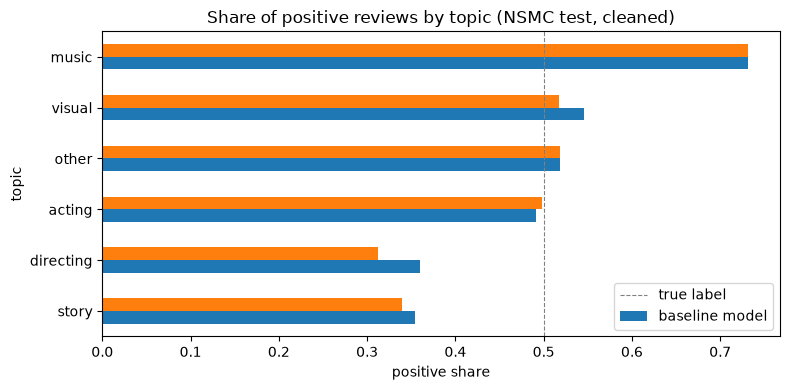

In [ ]:
import matplotlib.pyplot as plt

ax = topic_stat.set_index("topic")[["pos_rate_label", "pos_rate_model"]].plot.barh(figsize=(8, 4))
ax.set_title("Share of positive reviews by topic (NSMC test, cleaned)")
ax.set_xlabel("positive share")
ax.axvline(0.5, color="gray", lw=.8, ls="--")
ax.legend(["true label", "baseline model"])
plt.tight_layout()
plt.show()

마지막으로 Spark 와 MongoDB 를 끕니다.

In [ ]:
spark.stop()
mongod.terminate()
mongod.wait(timeout=30)
print("MongoDB 종료 코드:", mongod.returncode)

MongoDB 종료 코드: 0


## 10단계 · 더 해 보기

- 4단계의 길이 기준을 2글자에서 5글자로 올려 보세요. 정확도는 오르나요, 내리나요? 빠지는 리뷰 수와 함께 보세요.
- `ratings_train.txt`(15만 건)로 학습하고 이 프로젝트의 5만 건으로 평가해 보세요. 학습 데이터가 세 배가 되면 기준 모델이 얼마나 좋아지나요?
- LLM 태깅 결과(`llm`)를 Iceberg 에 `reviews.llm_tags` 테이블로 따로 쌓고, `id` 로 `nsmc_tagged` 와 조인해 보세요. 모델 결과를 원본 테이블에 덮어쓰지 않고 옆에 쌓는 것이 다시 계산하기 쉬운 설계입니다.